# Explore spinup inputs for GCAM-SCEPTER simulations
Each set of SCEPTER simulations uses one grid cell per GCAM region (n=32). The grid cell is selected by criteria commented alongside the spinup list. 

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmo
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import os

# ============================================================================================
#
# SPINLIST = [
#     "v1",                       # PmE runoff; porewater pH uses 15-30 cm horizon
#     "v2",                       # as v1 but max tPh = 7.0
#     "v3",                       # as v1 but tsoilco2 is doubled
#     "v1colombia",               # all sites have colombia's spinup inputs (the wettest site by far)
#     "v1_wettestSite",           # wettest P-E cell per GCAM region
#     "v1_wettestSite_crop25pct", # wettest P-E cell w >25% cropland
# ]
#
# ============================================================================================

# --- read in spinup data
SPINVERSION = "v1"
spin_csv_loc = "s3://carbonplan-carbon-removal/ew-workflows-data/scepter/batch"
spin_csv_fn = f"spinup_gcam_{SPINVERSION}.csv"
df = pd.read_csv(os.path.join(spin_csv_loc, spin_csv_fn))

# --- read in example map of gcam's 32 regions (for projecting spinup data onto)
RUNNAME_EXAMPLE = "exe_central1p5"
CROP_FRAC_EXAMPLE = "1.0-cropFraction"
DEG_RESOLUTION = 1
gcam_dir = f"s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/{RUNNAME_EXAMPLE}/{CROP_FRAC_EXAMPLE}"
gcam_fn = f'cropland+gcamRegions_time_{DEG_RESOLUTION}deg.zarr'
# [ read in ]
dsag = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))

In [17]:
# --- spinup file columns
df.columns

Index(['reg_id', 'region', 'region_nospaces', 'tsom', 'tph', 'tec', 'tsoilco2',
       'mat', 'poro', 'cec', 'qrun', 'soilmoisture', 'aws_bucket', 'aws_save',
       'tunespin_timeout', 'scepter_exec_name', 'skip_lab_run', 'spinname'],
      dtype='str')

## GCAM's 32 regions
GCAM splits the world into 32 regions (in the version we're using). Here's the map.

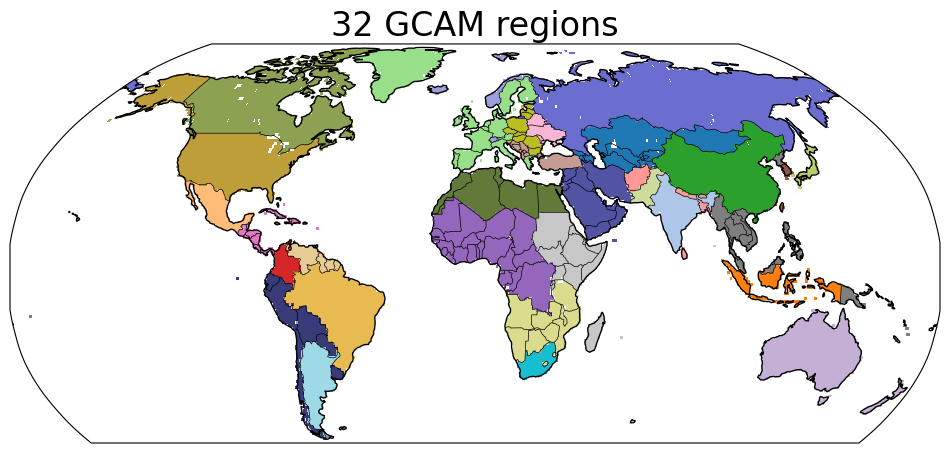

In [11]:
# ---------------------------------
# [ aesthetics ]
# color
mycmap = cmo.cm.tempo
# fonts
fs_title = 24
fs_legend_tick = 20
fs_legend_title= 20 
# extent
lon_min = -181
lon_max = 181
lat_min = -57
lat_max = 86
# ---------------------------------
# --- colors 
colors = list(
    plt.get_cmap("tab20").colors +
    plt.get_cmap("tab20b").colors
)
colors = colors[:32]   # ensure exactly 32
np.random.seed(42)     # reproducible shuffle
np.random.shuffle(colors)
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(np.arange(0.5, 33.5, 1), cmap.N)

# --- remove ocean cells
dsag['reg_id_plot'] = dsag['reg_id'].where(dsag['cropland_area_by_region'] != 0, other=np.nan)

# --- [ PLOT ]
da = dsag['reg_id_plot']

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot (important: specify transform!)
im = da.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),  # data are lat/lon
    cmap= cmap,
    norm=norm,
    add_colorbar=False,
    # cbar_kwargs={
    #     "orientation": "horizontal",
    #     "pad": 0.05,        # distance from plot
    #     "shrink": 0.8       # optional: make shorter
    # }
)
# # colorbar text
# cbar = im.colorbar
# cbar.ax.tick_params(labelsize=fs_legend_tick)
# cbar.set_label("", fontsize=fs_legend_title)
# extent + coasts
ax.set_extent([lon_min, lon_max, lat_min, lat_max],
              crs=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
# ax.set_global()
plt.title("32 GCAM regions", fontsize= fs_title)
plt.show()


## Spinup targets by GCAM region
Four panels:
- Target soil organic matter (`tsom`; weight percent)
- Target pH (`tph`; [])
- Target exchangeable acidity (`tec`; percent)
- Target soil $\text{CO}_2$ (`tsoilco2`; ppmv)

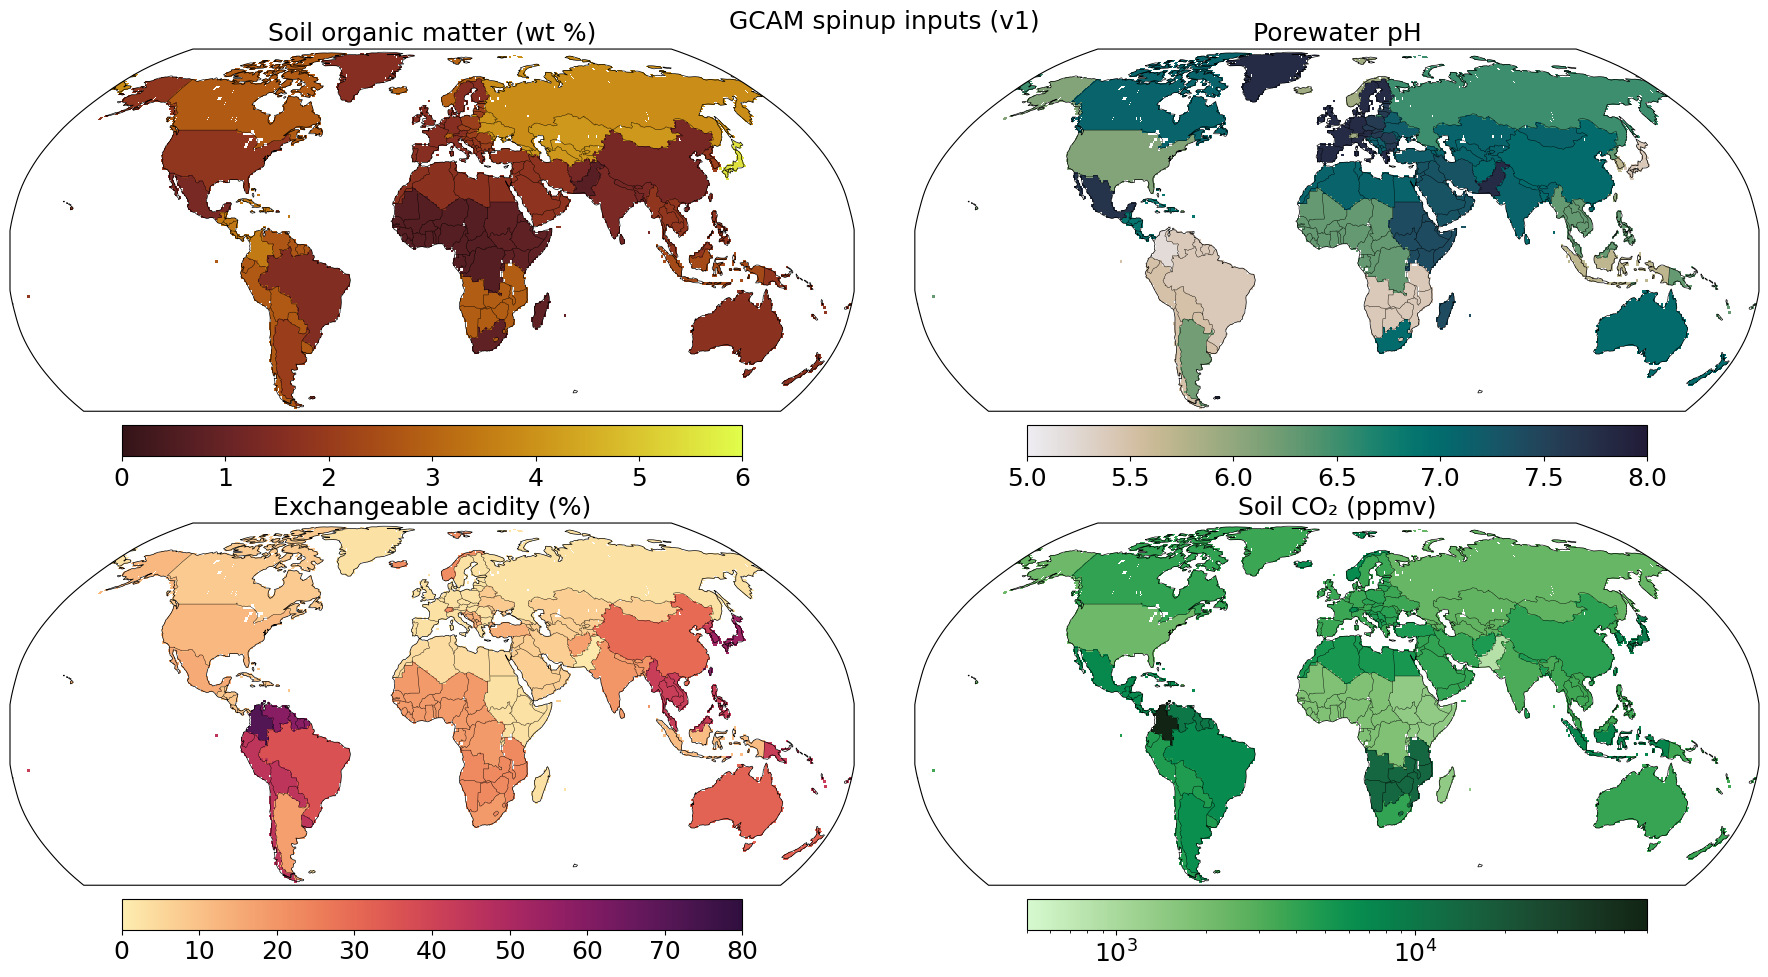

In [52]:
# ---------------------------------------
# [ aesthetics ]
# boundaries / lines
include_gcam_boundaries = False 
gcam_boundary_color = 'black'
gcam_boundary_lsize = 0.2 # (note gcam_boundary and coast_ are different scales)
coast_lsize = 0.5
borders_lsize = 0.3
# text
fs_panelTitle = 18
fs_mainTitle = 18
fs_cbar = 18
# ---------------------------------------

vars_to_plot = ['tsom', 'tph', 'tec', 'tsoilco2']
var_labels = {
    'tsom':    'Soil organic matter (wt %)',
    'tph':     'Porewater pH',
    'tec':     'Exchangeable acidity (%)',
    'tsoilco2':'Soil CO₂ (ppmv)',
}
cmaps = {
    'tsom':    cmo.cm.solar,
    'tph':     cmo.cm.rain,
    'tec':     cmo.cm.matter,
    'tsoilco2':cmo.cm.algae,
}
transforms = {
    'tsoilco2': lambda x: 10**x * 1e6,  # log10(atm) -> ppmv
}
norms = {
    'tsoilco2': mcolors.LogNorm(),
}
clims = {
    'tsom':     (0, 6),
    'tph':      (5., 8.),
    'tec':      (0, 80),
    'tsoilco2': (500, 60e3),
}

# Single time slice for spatial template and mask
reg_id_da  = dsag['reg_id']
ocean_mask = dsag['cropland_area_by_region'] == 0

# GCAM region boundaries: contour at half-integer levels traces where region IDs change
reg_id_boundary = reg_id_da.where(~ocean_mask)
boundary_levels = np.arange(0.5, 33.5, 1)

# Build reg_id -> value lookup for each variable
lookup = df.set_index('reg_id')

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 9.5),
    subplot_kw={'projection': ccrs.Robinson()},
    constrained_layout=True, 
)

for ax, var in zip(axes.flat, vars_to_plot):
    val_lookup = lookup[var].to_dict()

    mapped_vals = np.vectorize(lambda r: val_lookup.get(int(r), np.nan))(reg_id_da.values)
    if var in transforms:
        mapped_vals = transforms[var](mapped_vals)
    mapped_da = xr.DataArray(mapped_vals, coords=reg_id_da.coords, dims=reg_id_da.dims)
    mapped_da = mapped_da.where(~ocean_mask)

    vmin, vmax = clims[var]
    plot_kwargs = dict(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmaps[var],
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'pad': 0.03, 'shrink': 0.7},
        vmin=vmin,
        vmax=vmax,
    )
    if var in norms:
        norm = norms[var]
        norm.vmin, norm.vmax = vmin, vmax
        plot_kwargs['norm'] = norm
        plot_kwargs.pop('vmin'); plot_kwargs.pop('vmax')

    p = mapped_da.plot(**plot_kwargs)
    # tick label size
    p.colorbar.ax.tick_params(labelsize=fs_cbar)

    # overlay GCAM region boundaries
    if include_gcam_boundaries:
        reg_id_boundary.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=boundary_levels,
            colors=gcam_boundary_color,
            linewidths=gcam_boundary_lsize,
            add_colorbar=False,
        )

    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=coast_lsize)
    ax.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
    ax.set_title(var_labels[var], fontsize=fs_panelTitle)

plt.suptitle(f"GCAM spinup inputs ({SPINVERSION})", fontsize=fs_mainTitle, y=1.01)
plt.show()
plt.close();


In [53]:
# ---
df.columns

Index(['reg_id', 'region', 'region_nospaces', 'tsom', 'tph', 'tec', 'tsoilco2',
       'mat', 'poro', 'cec', 'qrun', 'soilmoisture', 'aws_bucket', 'aws_save',
       'tunespin_timeout', 'scepter_exec_name', 'skip_lab_run', 'spinname'],
      dtype='str')

## Climate inputs by GCAM region
Three panels:
- Mean annual temperature (`mat`; $\deg$C)
- Runoff (`qrun`; mm/yr)
- Soil moisture (`soilmoisture`; $\frac{m^3}{m^3}$)

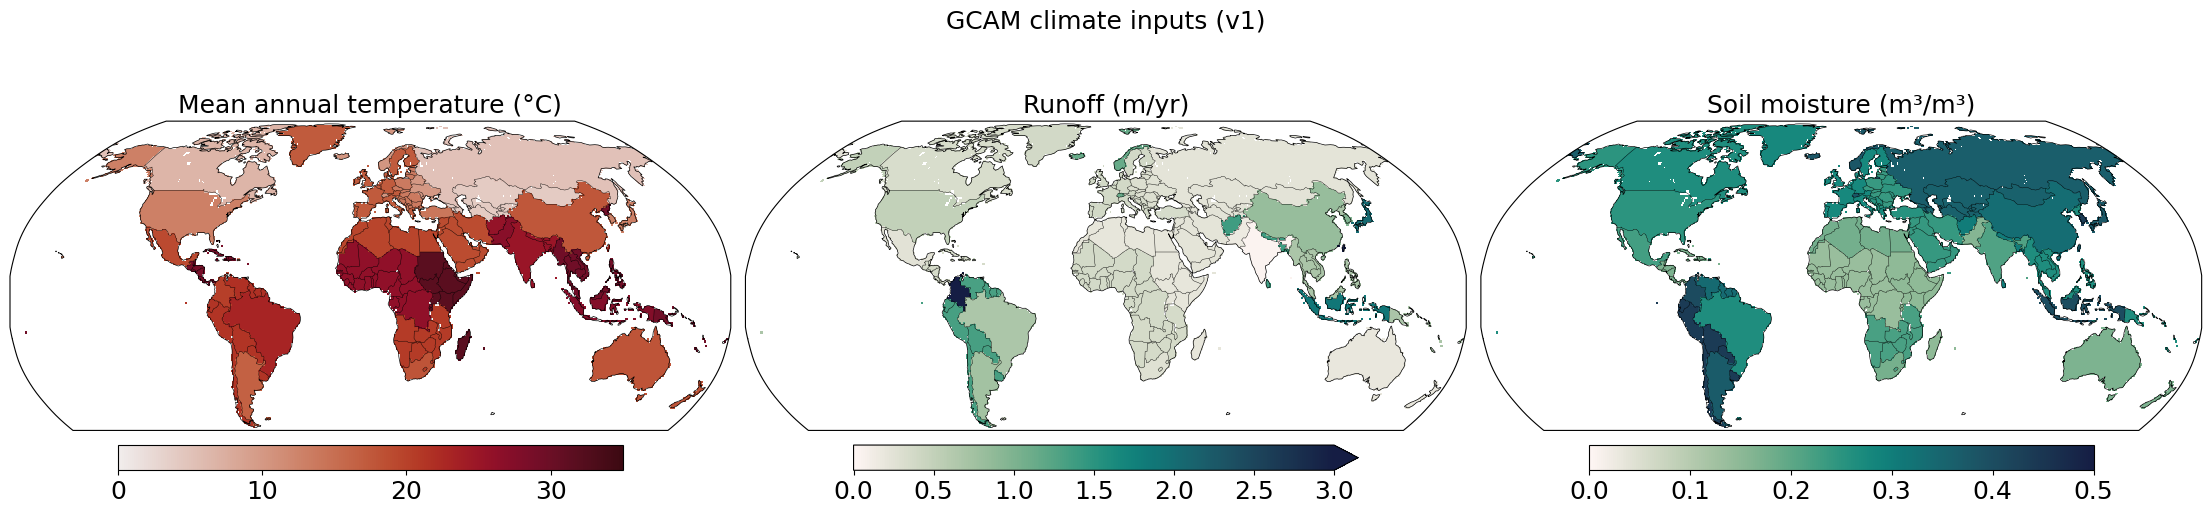

In [60]:
# ---------------------------------------
# [ aesthetics ]
# boundaries / lines
include_gcam_boundaries = False
gcam_boundary_color = 'black'
gcam_boundary_lsize = 0.2
coast_lsize = 0.5
borders_lsize = 0.3
# text
fs_panelTitle = 18
fs_mainTitle = 18
fs_cbar = 18
# ---------------------------------------

vars_to_plot = ['mat', 'qrun', 'soilmoisture']
var_labels = {
    'mat':         'Mean annual temperature (°C)',
    'qrun':        'Runoff (m/yr)',
    'soilmoisture':'Soil moisture (m³/m³)',
}
cmaps = {
    'mat':         cmo.cm.amp,
    'qrun':        cmo.cm.tempo,
    'soilmoisture':cmo.cm.tempo,
}
clims = {
    'mat':         (0, 35),
    'qrun':        (0, 3),
    'soilmoisture':(0, 0.5),
}

reg_id_da  = dsag['reg_id']
ocean_mask = dsag['cropland_area_by_region'] == 0
reg_id_boundary = reg_id_da.where(~ocean_mask)
boundary_levels = np.arange(0.5, 33.5, 1)
lookup = df.set_index('reg_id')

fig, axes = plt.subplots(
    1, 3,
    figsize=(22, 5),
    subplot_kw={'projection': ccrs.Robinson()},
    constrained_layout=True,
)

for ax, var in zip(axes.flat, vars_to_plot):
    val_lookup = lookup[var].to_dict()

    mapped_vals = np.vectorize(lambda r: val_lookup.get(int(r), np.nan))(reg_id_da.values)
    mapped_da = xr.DataArray(mapped_vals, coords=reg_id_da.coords, dims=reg_id_da.dims)
    mapped_da = mapped_da.where(~ocean_mask)

    vmin, vmax = clims[var]
    plot_kwargs = dict(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmaps[var],
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'pad': 0.03, 'shrink': 0.7},
        vmin=vmin,
        vmax=vmax,
    )

    p = mapped_da.plot(**plot_kwargs)
    p.colorbar.ax.tick_params(labelsize=fs_cbar)

    if include_gcam_boundaries:
        reg_id_boundary.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=boundary_levels,
            colors=gcam_boundary_color,
            linewidths=gcam_boundary_lsize,
            add_colorbar=False,
        )

    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=coast_lsize)
    ax.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
    ax.set_title(var_labels[var], fontsize=fs_panelTitle)

plt.suptitle(f"GCAM climate inputs ({SPINVERSION})", fontsize=fs_mainTitle)
plt.show()
plt.close();

## Soil physical inputs by GCAM region
Two panels:
- Porosity (`poro`; m³/m³)
- Cation exchange capacity (`cec`; cmolc/kg)

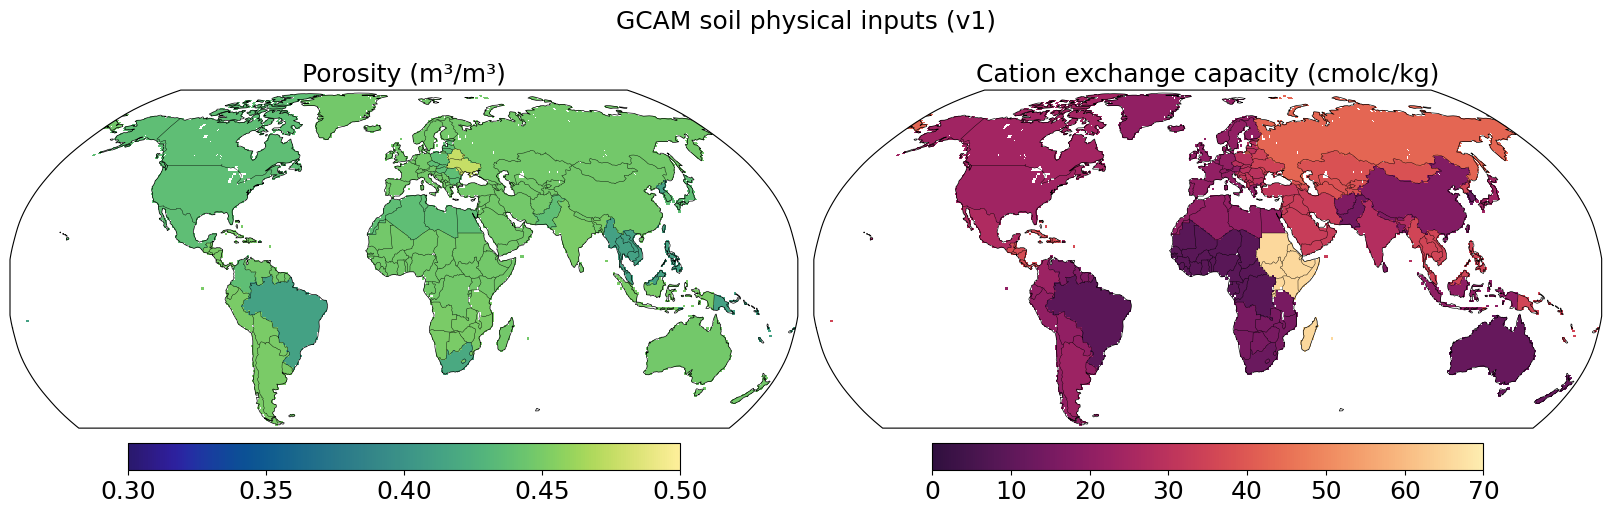

In [64]:
# ---------------------------------------
# [ aesthetics ]
include_gcam_boundaries = False
gcam_boundary_color = 'black'
gcam_boundary_lsize = 0.2
coast_lsize = 0.5
borders_lsize = 0.3
fs_panelTitle = 18
fs_mainTitle = 18
fs_cbar = 18
# ---------------------------------------

vars_to_plot = ['poro', 'cec']
var_labels = {
    'poro': 'Porosity (m³/m³)',
    'cec':  'Cation exchange capacity (cmolc/kg)',
}
cmaps = {
    'poro': cmo.cm.haline,
    'cec':  cmo.cm.matter_r,
}
clims = {
    'poro': (0.3, 0.5),
    'cec':  (0, 70),
}

reg_id_da  = dsag['reg_id']
ocean_mask = dsag['cropland_area_by_region'] == 0
reg_id_boundary = reg_id_da.where(~ocean_mask)
boundary_levels = np.arange(0.5, 33.5, 1)
lookup = df.set_index('reg_id')

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    subplot_kw={'projection': ccrs.Robinson()},
    constrained_layout=True,
)

for ax, var in zip(axes.flat, vars_to_plot):
    val_lookup = lookup[var].to_dict()

    mapped_vals = np.vectorize(lambda r: val_lookup.get(int(r), np.nan))(reg_id_da.values)
    mapped_da = xr.DataArray(mapped_vals, coords=reg_id_da.coords, dims=reg_id_da.dims)
    mapped_da = mapped_da.where(~ocean_mask)

    vmin, vmax = clims[var]
    plot_kwargs = dict(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmaps[var],
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'pad': 0.03, 'shrink': 0.7},
        vmin=vmin,
        vmax=vmax,
    )

    p = mapped_da.plot(**plot_kwargs)
    p.colorbar.ax.tick_params(labelsize=fs_cbar)

    if include_gcam_boundaries:
        reg_id_boundary.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=boundary_levels,
            colors=gcam_boundary_color,
            linewidths=gcam_boundary_lsize,
            add_colorbar=False,
        )

    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=coast_lsize)
    ax.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
    ax.set_title(var_labels[var], fontsize=fs_panelTitle)

plt.suptitle(f"GCAM soil physical inputs ({SPINVERSION})", fontsize=fs_mainTitle)
plt.show()
plt.close();

## Combined: target + soil physical inputs
Six panels (2 columns × 3 rows): target variables (`tsom`, `tph`, `tec`, `tsoilco2`) on top, soil physical inputs (`poro`, `cec`) on bottom.

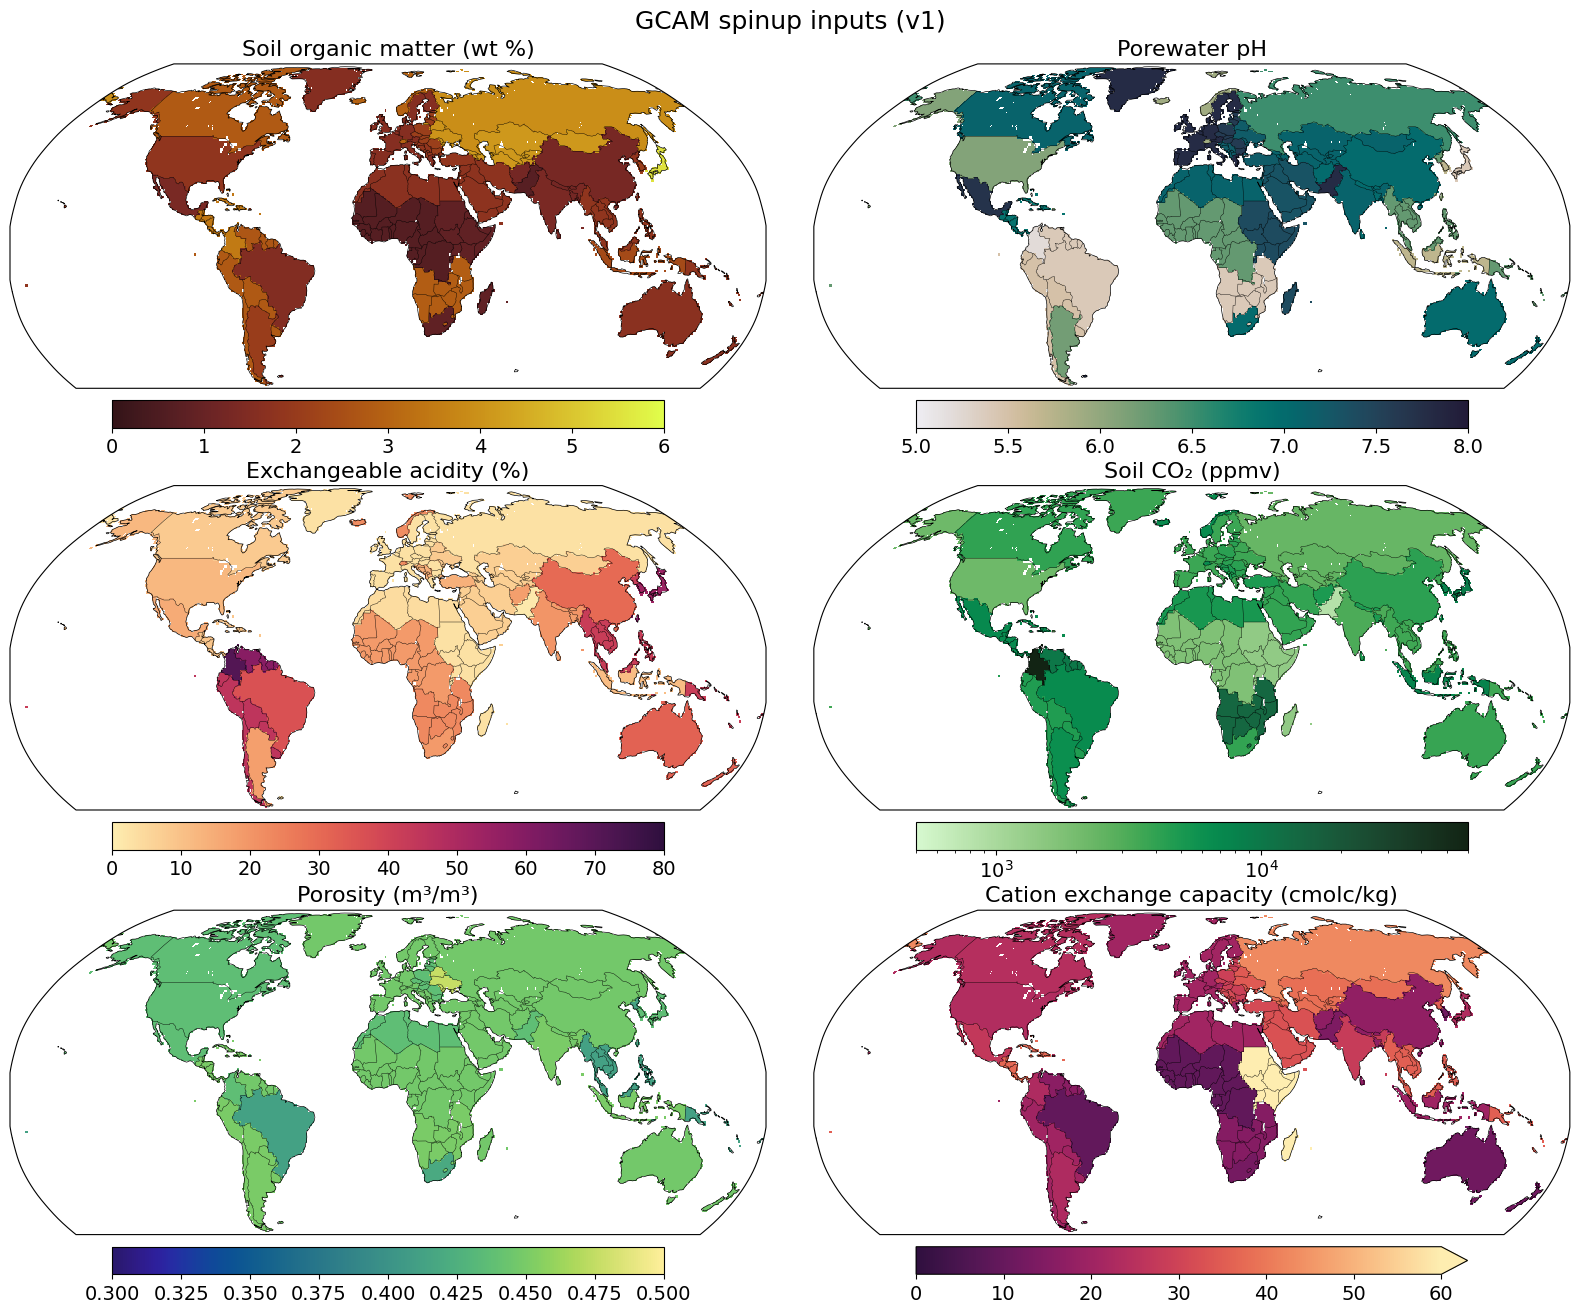

In [66]:
# ---------------------------------------
# [ aesthetics ]
include_gcam_boundaries = False
gcam_boundary_color = 'black'
gcam_boundary_lsize = 0.2
coast_lsize = 0.5
borders_lsize = 0.3
fs_panelTitle = 16
fs_mainTitle = 18
fs_cbar = 14
# ---------------------------------------

vars_to_plot = ['tsom', 'tph', 'tec', 'tsoilco2', 'poro', 'cec']
var_labels = {
    'tsom':     'Soil organic matter (wt %)',
    'tph':      'Porewater pH',
    'tec':      'Exchangeable acidity (%)',
    'tsoilco2': 'Soil CO₂ (ppmv)',
    'poro':     'Porosity (m³/m³)',
    'cec':      'Cation exchange capacity (cmolc/kg)',
}
cmaps = {
    'tsom':     cmo.cm.solar,
    'tph':      cmo.cm.rain,
    'tec':      cmo.cm.matter,
    'tsoilco2': cmo.cm.algae,
    'poro':     cmo.cm.haline,
    'cec':      cmo.cm.matter_r,
}
transforms = {
    'tsoilco2': lambda x: 10**x * 1e6,
}
norms_cfg = {
    'tsoilco2': mcolors.LogNorm(),
}
clims = {
    'tsom':     (0, 6),
    'tph':      (5., 8.),
    'tec':      (0, 80),
    'tsoilco2': (500, 60e3),
    'poro':     (0.3, 0.5),
    'cec':      (0, 60),
}

reg_id_da  = dsag['reg_id']
ocean_mask = dsag['cropland_area_by_region'] == 0
reg_id_boundary = reg_id_da.where(~ocean_mask)
boundary_levels = np.arange(0.5, 33.5, 1)
lookup = df.set_index('reg_id')

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 13),
    subplot_kw={'projection': ccrs.Robinson()},
    constrained_layout=True,
)

for ax, var in zip(axes.flat, vars_to_plot):
    val_lookup = lookup[var].to_dict()

    mapped_vals = np.vectorize(lambda r: val_lookup.get(int(r), np.nan))(reg_id_da.values)
    if var in transforms:
        mapped_vals = transforms[var](mapped_vals)
    mapped_da = xr.DataArray(mapped_vals, coords=reg_id_da.coords, dims=reg_id_da.dims)
    mapped_da = mapped_da.where(~ocean_mask)

    vmin, vmax = clims[var]
    plot_kwargs = dict(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmaps[var],
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'pad': 0.03, 'shrink': 0.7},
        vmin=vmin,
        vmax=vmax,
    )
    if var in norms_cfg:
        norm = norms_cfg[var]
        norm.vmin, norm.vmax = vmin, vmax
        plot_kwargs['norm'] = norm
        plot_kwargs.pop('vmin'); plot_kwargs.pop('vmax')

    p = mapped_da.plot(**plot_kwargs)
    p.colorbar.ax.tick_params(labelsize=fs_cbar)

    if include_gcam_boundaries:
        reg_id_boundary.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=boundary_levels,
            colors=gcam_boundary_color,
            linewidths=gcam_boundary_lsize,
            add_colorbar=False,
        )

    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=coast_lsize)
    ax.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
    ax.set_title(var_labels[var], fontsize=fs_panelTitle)

plt.suptitle(f"GCAM spinup inputs ({SPINVERSION})", fontsize=fs_mainTitle)
plt.show()
plt.close();

In [ ]:
# ---